In [1]:
!pip -q install sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 10.3 MB/s eta 0:00:00


In [2]:
import os
import re
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from tqdm.notebook import tqdm
from sacrebleu.metrics import BLEU, CHRF

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [3]:
from google.colab import files

uploaded = files.upload()

zip_name = next(
    name for name in uploaded if name.endswith(".zip")
)

extract_dir = "/content/translation_data"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully!")

Saving archive.zip to archive.zip
Dataset extracted successfully!


In [5]:
import glob

def find_file(filename):
    matches = glob.glob(
        os.path.join(extract_dir, "**", filename),
        recursive=True
    )
    if not matches:
        raise FileNotFoundError(f"{filename} not found in ZIP file")
    return matches[0]

def load_data(path):
    pairs = []

    with open(path, "r", encoding="utf-8-sig") as f:
        for line in f:
            parts = line.rstrip("\n\r").split("\t", 1)

            if len(parts) == 2:
                english = parts[0].strip()
                target = parts[1].strip()

                if english and target:
                    pairs.append((english, target))

    return pd.DataFrame(pairs, columns=["english", "target"])

train_df = load_data(find_file("train.txt"))
val_df = load_data(find_file("dev.txt"))
test_df = load_data(find_file("test.txt"))

print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Testing pairs:", len(test_df))

display(train_df.head())

Training pairs: 7040
Validation pairs: 1020
Testing pairs: 942


,english,target
0,Batman vs Superman,batman vs superman
1,"The director is Zack Snyder , 27 % Rotten Toma...","Zack Snyder director हैं , 27 % Rotten Tomatoe..."
2,Not very popular it seems,लगता है बहुत popular नहीं है
3,But the audiences liked it . It has a B cinema...,"but audience ने like किया , इसका cinema score ..."
4,Yes,yes


In [6]:
PAD_ID = 0
UNK_ID = 1
BOS_ID = 2
EOS_ID = 3

MAX_LEN = 30
MAX_VOCAB = 12000

def tokenize(sentence):
    return re.findall(
        r"\w+|[^\w\s]",
        sentence.lower(),
        flags=re.UNICODE
    )

def build_vocab(sentences):
    counts = Counter()

    for sentence in sentences:
        counts.update(tokenize(sentence))

    vocab = {
        "<pad>": PAD_ID,
        "<unk>": UNK_ID,
        "<bos>": BOS_ID,
        "<eos>": EOS_ID
    }

    for word, count in counts.most_common(MAX_VOCAB - len(vocab)):
        if word not in vocab:
            vocab[word] = len(vocab)

    return vocab

src_stoi = build_vocab(train_df["english"])
tgt_stoi = build_vocab(train_df["target"])

print("English vocabulary:", len(src_stoi))
print("Target vocabulary:", len(tgt_stoi))

English vocabulary: 5439
Target vocabulary: 5253


In [7]:
def encode_sentence(sentence, vocab):
    tokens = tokenize(sentence)
    tokens = tokens[:MAX_LEN - 2]

    ids = [BOS_ID]
    ids += [vocab.get(word, UNK_ID) for word in tokens]
    ids += [EOS_ID]

    return torch.tensor(ids, dtype=torch.long)

class TranslationDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        source = encode_sentence(row["english"], src_stoi)
        target = encode_sentence(row["target"], tgt_stoi)

        return source, target

def collate_batch(batch):
    sources, targets = zip(*batch)

    lengths = torch.tensor(
        [len(source) for source in sources],
        dtype=torch.long
    )

    sources = pad_sequence(
        sources, batch_first=True, padding_value=PAD_ID
    )

    targets = pad_sequence(
        targets, batch_first=True, padding_value=PAD_ID
    )

    return sources, lengths, targets

BATCH_SIZE = 128

train_loader = DataLoader(
    TranslationDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    TranslationDataset(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 55
Validation batches: 8


In [8]:
EMBED_SIZE = 128
HIDDEN_SIZE = 128

class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, EMBED_SIZE, padding_idx=PAD_ID
        )
        self.lstm = nn.LSTM(
            EMBED_SIZE, HIDDEN_SIZE, batch_first=True
        )

    def forward(self, source, lengths):
        embedded = self.embedding(source)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, cell) = self.lstm(packed)

        return hidden, cell


class Decoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, EMBED_SIZE, padding_idx=PAD_ID
        )
        self.lstm = nn.LSTM(
            EMBED_SIZE, HIDDEN_SIZE, batch_first=True
        )
        self.output = nn.Linear(HIDDEN_SIZE, vocab_size)

    def forward(self, token, hidden, cell):
        token = token.unsqueeze(1)
        embedded = self.embedding(token)

        output, (hidden, cell) = self.lstm(
            embedded, (hidden, cell)
        )

        logits = self.output(output.squeeze(1))

        return logits, hidden, cell


class Seq2Seq(nn.Module):
    def __init__(self, source_vocab_size, target_vocab_size):
        super().__init__()
        self.encoder = Encoder(source_vocab_size)
        self.decoder = Decoder(target_vocab_size)

    def forward(self, source, lengths, target, teacher_forcing_ratio=0.5):
        hidden, cell = self.encoder(source, lengths)

        token = target[:, 0]
        outputs = []

        for step in range(1, target.size(1)):
            logits, hidden, cell = self.decoder(
                token, hidden, cell
            )

            outputs.append(logits)

            predicted = logits.argmax(dim=1)

            if random.random() < teacher_forcing_ratio:
                token = target[:, step]
            else:
                token = predicted

        return torch.stack(outputs, dim=1)


model = Seq2Seq(
    len(src_stoi),
    len(tgt_stoi)
).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

print(model)
print("Model ready on:", DEVICE)

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(5439, 128, padding_idx=0)
    (lstm): LSTM(128, 128, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(5253, 128, padding_idx=0)
    (lstm): LSTM(128, 128, batch_first=True)
    (output): Linear(in_features=128, out_features=5253, bias=True)
  )
)
Model ready on: cpu


In [10]:
EPOCHS = 5
TEACHER_FORCING_RATIO = 0.5

def run_epoch(loader, training):
    model.train() if training else model.eval()

    total_loss = 0
    total_correct = 0
    total_tokens = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    )

    for source, lengths, target in progress:
        source = source.to(DEVICE)
        target = target.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(
                source,
                lengths,
                target,
                TEACHER_FORCING_RATIO if training else 1.0
            )

            labels = target[:, 1:]
            vocab_size = logits.size(-1)

            loss_sum = nn.functional.cross_entropy(
                logits.reshape(-1, vocab_size),
                labels.reshape(-1),
                ignore_index=PAD_ID,
                reduction="sum"
            )

            valid = labels != PAD_ID
            token_count = valid.sum()

            if training:
                loss = loss_sum / token_count.clamp(min=1)
                loss.backward()

                nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0
                )

                optimizer.step()

        predictions = logits.argmax(dim=-1)

        correct = ((predictions == labels) & valid).sum().item()

        total_loss += loss_sum.item()
        total_correct += correct
        total_tokens += token_count.item()

        progress.set_postfix(
            loss=f"{loss_sum.item() / max(token_count.item(), 1):.3f}"
        )

    avg_loss = total_loss / max(total_tokens, 1)
    accuracy = 100 * total_correct / max(total_tokens, 1)

    return avg_loss, accuracy


history = []

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")

    train_loss, train_acc = run_epoch(train_loader, True)
    val_loss, val_acc = run_epoch(val_loader, False)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Token Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Token Accuracy: {val_acc:.2f}%")

history_df = pd.DataFrame(history)
display(history_df)


Epoch 1/5


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 4.6387
Training Token Accuracy: 9.53%
Validation Loss: 4.5378
Validation Token Accuracy: 13.69%

Epoch 2/5


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Training Loss: 4.1773
Training Token Accuracy: 20.61%
Validation Loss: 3.8937
Validation Token Accuracy: 29.43%

Epoch 5/5


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 4.0759
Training Token Accuracy: 22.20%
Validation Loss: 3.7704
Validation Token Accuracy: 30.67%


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,4.638660,9.528649,4.537797,13.687207
1,2,4.478708,14.218872,4.313309,21.611905
2,3,4.326936,17.348746,4.076310,26.465595
3,4,4.177317,20.609179,3.893670,29.426745
4,5,4.075930,22.203403,3.770401,30.670129


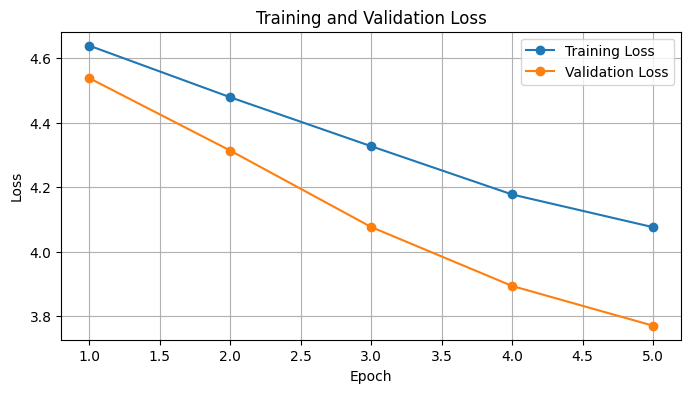

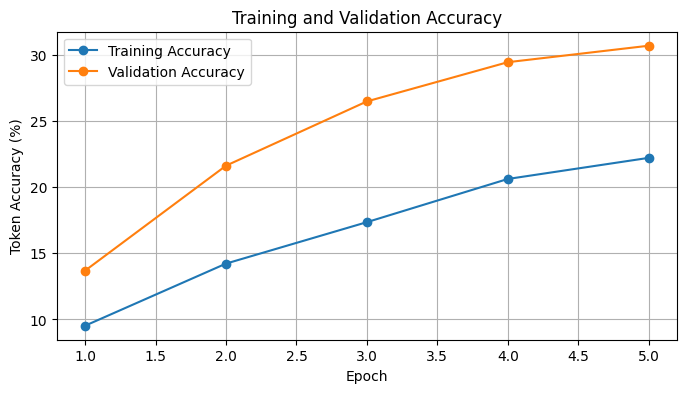

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["train_loss"],
         marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"],
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["train_accuracy"],
         marker="o", label="Training Accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"],
         marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Token Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
tgt_itos = {index: word for word, index in tgt_stoi.items()}

def translate(sentence):
    model.eval()

    source_ids = encode_sentence(sentence, src_stoi)
    source = source_ids.unsqueeze(0).to(DEVICE)
    lengths = torch.tensor([len(source_ids)])

    output_words = []

    with torch.no_grad():
        hidden, cell = model.encoder(source, lengths)

        token = torch.tensor([BOS_ID], device=DEVICE)

        for _ in range(MAX_LEN):
            logits, hidden, cell = model.decoder(
                token, hidden, cell
            )

            next_id = logits.argmax(dim=1).item()

            if next_id == EOS_ID:
                break

            if next_id not in (PAD_ID, BOS_ID):
                output_words.append(
                    tgt_itos.get(next_id, "<unk>")
                )

            token = torch.tensor([next_id], device=DEVICE)

    return " ".join(output_words)

In [ ]:
sentences = [
    "Where are you going?",
    "I want to learn something new.",
    "Please help me.",
    "Today is a beautiful day.",
    "I am preparing for my examination."
]

for i, sentence in enumerate(sentences, 1):
    print(f"{i}. English: {sentence}")
    print("Translation:", translate(sentence))
    print("-" * 40)

In [13]:
test_predictions = []
test_references = []

model.eval()

for _, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Testing"
):
    test_predictions.append(translate(row["english"]))
    test_references.append(row["target"])

bleu_score = BLEU().corpus_score(
    test_predictions, [test_references]
).score

chrf_score = CHRF().corpus_score(
    test_predictions, [test_references]
).score

print(f"BLEU Score: {bleu_score:.2f}")
print(f"chrF Score: {chrf_score:.2f}")

results_df = pd.DataFrame({
    "English": test_df["english"].tolist(),
    "Actual Translation": test_references,
    "Predicted Translation": test_predictions
})

display(results_df.head(10))

Testing:   0%|          | 0/942 [00:00<?, ?it/s]

BLEU Score: 0.01
chrF Score: 6.15


,English,Actual Translation,Predicted Translation
0,hello,hello,hello
1,"hello there , I have not seen this movie so im...","हैलो यार , मैं इस movie को नहीं देख हों तो , त...",म ु झ े ं ा ह ै ं क े ं ा ह ै ं क े ं ा ह ै ं ...
2,Alright that is fine . What is the movie ?,अच्छा तो इस movie किस बारे में हैं ?,क ् य ा क ा ह ै ं े क े ं ा ह ै ं
3,The movie is The Social Network,is movie tho social network के बारे में हैं,म ु झ े ं ा ह ै ं
4,I have not seen that one either .,मैं ऐसे कुछ नहीं देखा हूँ,म ु झ े ं ा ह ै ं े ं ा ह ै ं
5,It appears to be like a biographical movie abo...,"यह तो biographical movie की तरह हैं , mark zuk...","म ै ं , म े ं ा ह ै ं क े ं ा ह ै ं े क े ं ा ..."
6,"Ohh yes I remember hearing about that movie , ...",हाँ यार . में भी इस movie के बारे में सुना हूँ...,म ै ं े ं ा ह ै ं क े ं ा ह ै ं क े ं ा ह ै ं ...
7,Rotten Tomatoes has rated it 96 % so that's de...,Rotten Tomatoes ने तो 96 % दिया था और यह movie...,"म ु ं , म े ं ा ह ै ं क ि य ा ह ै ं क े ं ा ह ै ं"
8,may be worth watching !,हाँ worth watching हैं,ह ै ं ा ह ै
9,"Yes I think it could be , although I personall...","हाँ मुझे भी ऐसे ही लगता , लेकिन personally मुझ...",म ै ं े ं ा ह ै ं क े ं ा ह ै ं क े ं ा ह ै ं


In [14]:
while True:
    sentence = input("Enter English sentence (or 'exit'): ")

    if sentence.strip().lower() == "exit":
        print("Finished!")
        break

    if sentence.strip():
        print("Translation:", translate(sentence))
        print("-" * 40)
    else:
        print("Please enter a sentence.")

Enter English sentence (or 'exit'): HELLO I AM A GOOD SINGER
Translation: म ु झ े ं ा ह ै ं
----------------------------------------
Enter English sentence (or 'exit'): exit
Finished!
